# UrbanNest Hospitality Analytics

## Hotel Booking Revenue Analysis

### Hospitality Capstone Project 

**Objective:**
To analyze hotel booking patterns, customer behaviour, revenue performance, develop a model that helps explain and predict booking revenue.

**Team:** 

          DATA CLEANING
          1) Amaka Igbonezim

          EDA
          1) Abdulazeez Sani
          2) Salihu Kabiru Omeiza
          3) Louis Mbagwu
          4) Durojaiye Tosin Eniola
          

          SQL ANALYSIS
          1) Jacinta Syokau
          2) Stephen Bonu

          MODELLING
          1) Shalom Okanlawon
          2) Dunmiye Bunmi
          3) Nwoba Anayo
          

          INTERPRETATION AND COEFFICIENTS
          1) Aanu Adesemoye

          DELIVERABLE ASSEMBLY
          1) Elenwo Chikem
          


**Date:** 5th October, 2026

# Table of Contents
1. Executive Summary
2. Business Problem & Objectives
3. Dataset Overview
4. Data Loading & Initial Inspection
5. Data Cleaning
6. Exploratory Data Analysis
   - 6.1 Hotel Type Distribution
   - 6.2 Revenue Distribution
   - 6.3 Revenue by Hotel Type
   - 6.4 Revenue by Reserved Room Type
   - 6.5 Average Revenue by Customer Type
   - 6.6 Booking Activity by Month
   - 6.7 Market Segment Analysis
   - 6.8 Length of Stay vs Revenue
   - 6.9 Lead Time vs Revenue
   - 6.10 Correlation Analysis
7. SQL Analysis
8. Feature Engineering & Preprocessing
9. Linear Regression Model
10. Model Evaluation
   - 10.1 Statistical Significance
   - 10.2 Regression Assumptions
   - 10.3 Time-Based Validation
   - 10.4 Improved Model: Interaction Terms
11. Interpretation of Coefficients
12. Business Impact Sizing
13. Interactive Booking Value Estimator
14. Integrated Findings
15. Recommendations
16. Ethics, Privacy & Responsible Use
17. Conclusion
- Appendix A: Data Dictionary
- Appendix B: Brief Compliance Checklist

# 1. Executive Summary

## Project Overview
This project analyzes 85,501 cleaned hotel bookings (City Hotel and Resort Hotel, July 2015 – August 2017) to understand the factors associated with booking revenue and customer booking behaviour. It combines data cleaning, exploratory data analysis, SQL analysis and linear regression modelling to generate business insights for UrbanNest Hospitality Analytics.

*All monetary values are in euros (€). The hotels are in Portugal, and ADR is recorded in EUR.*

### Key Questions
- What factors are associated with hotel revenue?
- Which hotel and room types generate higher average revenue?
- Which months have the highest booking activity?
- How does length of stay relate to revenue?
- How does lead time relate to revenue?
- Can booking characteristics be used to predict revenue?

### Headline Results
- **27.8% of bookings were cancelled**, representing **€11.43M (33.3%)** of the €34.31M total booking value.
- **Online TA** bookings cancel at **35.5%**, compared with about **15%** for Direct and Offline TA/TO.
- **Length of stay** is the strongest single driver of revenue (correlation 0.75; about **+€97 per extra night** in the model).
- The **official Linear Regression model** (the modelling team's 16 features plus interaction terms) explains about **84% of the variation in booking value** (test R² 0.844) with an average error of about **€91**, which is **64% lower** than a naive baseline. It also holds up on 2017 bookings (R² 0.82).
- Illustrative sizing: cutting Online TA cancellations by 5 percentage points would retain about **€0.6M per year**.

# 2. Business Problem & Objectives

## Business Problem
Hotels sell a perishable product: an unsold or cancelled room-night cannot be sold later. Many hotels still set prices and plan capacity on intuition, which leads to missed revenue in peak periods and under-performance in low season.

UrbanNest wants to understand what drives booking revenue and whether booking and customer characteristics can be used to predict it.

**Why predicting revenue matters**
- **Pricing:** shows which attributes (season, room type, length of stay, segment) carry more value.
- **Occupancy:** combined with cancellation patterns, supports deposit and overbooking decisions.
- **Profitability:** shows which channels and segments deliver the most reliable value.

## Objectives
1. Examine the structure and quality of the hotel booking dataset.
2. Clean and prepare the data for analysis.
3. Explore booking patterns and revenue performance.
4. Use SQL to answer key business questions.
5. Identify relationships between booking characteristics and revenue.
6. Build a Linear Regression model to predict revenue.
7. Evaluate the model's performance.
8. Translate analytical findings into practical business recommendations.

# 3. Dataset Overview

## Dataset Description
The Hotel Booking Demand dataset contains booking characteristics, customer information, stay details, room information, market segments and pricing (ADR = average daily rate). It has no revenue column, so revenue is derived as:

**revenue = ADR × total nights**

Because cancelled bookings keep their ADR, revenue for a cancelled booking is the value that was **booked but not realized**. We therefore refer to it as **booking value** and separate cancelled from non-cancelled bookings wherever it matters.

In [1]:
import sqlite3
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import statsmodels.api as sm

%matplotlib inline
sns.set_theme(style='whitegrid')

MONTHS = ['January', 'February', 'March', 'April', 'May', 'June', 'July',
          'August', 'September', 'October', 'November', 'December']
STATUS = {0: 'Not cancelled', 1: 'Cancelled'}

# 4. Data Loading & Initial Inspection
We start from the **raw** dataset so the full workflow (inspection → cleaning → analysis) is reproducible in one notebook.

In [2]:
raw = pd.read_csv('hotel_bookings.csv')
print('Shape:', raw.shape)
raw.head()

Shape: (119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

In [4]:
raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
is_canceled,119390.0,0.37,0.48,0.00,0.00,0.00,1.0,1.0
lead_time,119390.0,104.01,106.86,0.00,18.00,69.00,160.0,737.0
arrival_date_year,119390.0,2016.16,0.71,2015.00,2016.00,2016.00,2017.0,2017.0
arrival_date_week_number,119390.0,27.17,13.61,1.00,16.00,28.00,38.0,53.0
arrival_date_day_of_month,119390.0,15.80,8.78,1.00,8.00,16.00,23.0,31.0
stays_in_weekend_nights,119390.0,0.93,1.00,0.00,0.00,1.00,2.0,19.0
stays_in_week_nights,119390.0,2.50,1.91,0.00,1.00,2.00,3.0,50.0
adults,119390.0,1.86,0.58,0.00,2.00,2.00,2.0,55.0
children,119386.0,0.10,0.40,0.00,0.00,0.00,0.0,10.0
babies,119390.0,0.01,0.10,0.00,0.00,0.00,0.0,10.0


In [5]:
missing = raw.isna().sum()
print('Missing values (columns with gaps):')
print(missing[missing > 0].sort_values(ascending=False))
print('\nExact duplicate rows:', raw.duplicated().sum())

Missing values (columns with gaps):
company     112593
agent        16340
country        488
children         4
dtype: int64



Exact duplicate rows: 31994


In [6]:
print('Categorical columns:', raw.select_dtypes('object').columns.tolist())
print('\nNumerical columns:', raw.select_dtypes('number').columns.tolist())

Categorical columns: ['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'assigned_room_type', 'deposit_type', 'customer_type', 'reservation_status', 'reservation_status_date']

Numerical columns: ['is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'agent', 'company', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests']


### Inspection Findings
- **119,390 bookings × 32 columns** for two hotels, arriving between July 2015 and August 2017.
- **Missing values:** `company` (94%), `agent` (14%), `country` (488 rows), `children` (4 rows).
- **31,994 exact duplicate rows** are present on the raw columns. After `agent`/`company` are dropped, **32,020** rows become duplicates, which is the number removed in Section 5.
- **Invalid records:** stays of 0 nights, ADR ≤ 0 (including one negative value) and one extreme ADR of 5,400.
- `reservation_status`, `reservation_status_date` and `assigned_room_type` are only known **after** the guest arrives, so they cannot be used to predict revenue at booking time.

# 5. Data Cleaning
*Data cleaning: Amaka Igbonezim.* These steps reproduce `hotel_bookings_clean.csv` exactly (85,501 rows).

In [7]:
df = raw.copy()
log = [('Raw data', len(df))]

# 1. Drop ID columns with heavy missingness
df = df.drop(columns=['agent', 'company'])

# 2. Handle missing values
df['children'] = df['children'].fillna(0)
df['country']  = df['country'].fillna('Unknown')

# 3. Remove duplicates
df = df.drop_duplicates();                         log.append(('Remove duplicates', len(df)))

# 4. Create revenue variables
df['total_nights'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']
df['revenue']      = df['adr'] * df['total_nights']

# 5. Remove invalid / extreme records
df = df[df['total_nights'] > 0];                   log.append(('Remove 0-night stays', len(df)))
df = df[df['adr'] > 0];                            log.append(('Remove ADR <= 0', len(df)))
df = df[df['adr'] < 335];                          log.append(('Remove extreme ADR (>= 335, top 0.1%)', len(df)))

clean_log = pd.DataFrame(log, columns=['step', 'rows_remaining'])
clean_log['rows_removed'] = (-clean_log['rows_remaining'].diff()).fillna(0).astype(int)
print(clean_log.to_string(index=False))
print('\nRemaining missing values:', df.isna().sum().sum(), '| duplicates:', df.duplicated().sum())
assert len(df) == 85501, 'Row count does not match hotel_bookings_clean.csv'
df.to_csv('hotel_bookings_clean.csv', index=False)

                                 step  rows_remaining  rows_removed
                             Raw data          119390             0
                    Remove duplicates           87370         32020
                 Remove 0-night stays           86719           651
                      Remove ADR <= 0           85591          1128
Remove extreme ADR (>= 335, top 0.1%)           85501            90

Remaining missing values: 0 | duplicates: 0


In [8]:
# Helper columns used in EDA and SQL
df['month_number'] = df['arrival_date_month'].map({m: i + 1 for i, m in enumerate(MONTHS)})
df['arrival_date_month'] = pd.Categorical(df['arrival_date_month'], categories=MONTHS, ordered=True)
df['booking_status'] = df['is_canceled'].map(STATUS)
non_cancelled = df[df['is_canceled'] == 0].copy()
print(f'Bookings: {len(df):,} | Non-cancelled: {len(non_cancelled):,} | Cancelled: {df.is_canceled.sum():,} ({df.is_canceled.mean():.1%})')

Bookings: 85,501 | Non-cancelled: 61,694 | Cancelled: 23,807 (27.8%)


### 5.1 Remaining data-quality issues (flagged, handled at modelling stage)

In [9]:
issues = pd.Series({
    'Bookings with 0 adults': (df['adults'] == 0).sum(),
    'Children or babies > 3': ((df['children'] > 3) | (df['babies'] > 3)).sum(),
    'Stays longer than 21 nights': (df['total_nights'] > 21).sum(),
    "meal = 'Undefined'": (df['meal'] == 'Undefined').sum(),
    "market_segment = 'Undefined'": (df['market_segment'] == 'Undefined').sum(),
    'Room type L (tiny sample)': (df['reserved_room_type'] == 'L').sum(),
})
issues.to_frame('rows')

,rows
Bookings with 0 adults,244
Children or babies > 3,3
Stays longer than 21 nights,124
meal = 'Undefined',456
market_segment = 'Undefined',2
Room type L (tiny sample),6


**Cleaning summary.** The dataset now has no missing values or duplicates. A small number of unusual records remain, and they are handled in Section 8:
- **Bookings with 0 adults** are not realistic reservations. They are removed from the modelling data.
- **Meal 'Undefined'** means the same as SC (no meal package) according to the dataset documentation. It is re-coded as SC.
- **Market segment 'Undefined'** has only 2 rows. They are removed so they don't produce meaningless model coefficients.
- **Room type L** has only 6 bookings, so averages for L are unreliable and are excluded from the room charts.

# 6. Exploratory Data Analysis

## 6.1 Hotel Type Distribution

hotel
City Hotel      52324
Resort Hotel    33177
Name: count, dtype: int64


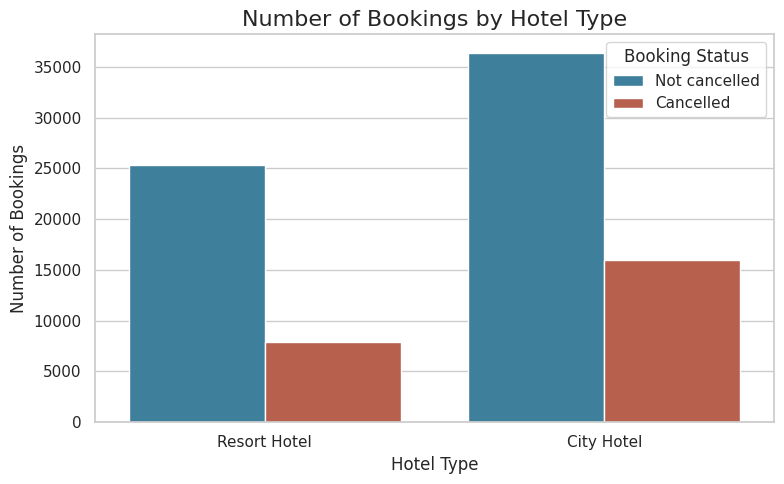

hotel
City Hotel      30.5
Resort Hotel    23.7
Name: cancellation_rate_%, dtype: float64


In [10]:
hotel_counts = df['hotel'].value_counts()
print(hotel_counts)
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='hotel', hue='booking_status', palette=['#2E86AB', '#C8553D'])
plt.title('Number of Bookings by Hotel Type', fontsize=16)
plt.xlabel('Hotel Type'); plt.ylabel('Number of Bookings'); plt.legend(title='Booking Status')
plt.tight_layout(); plt.show()
print(df.groupby('hotel')['is_canceled'].mean().mul(100).round(1).rename('cancellation_rate_%'))

### Finding
City Hotel accounts for **52,324 bookings (61%)** and Resort Hotel for **33,177 (39%)**. City Hotel also cancels more often: **about 30% vs 24%**.

### Business Meaning
City Hotel is the main source of booking volume, but it carries more cancellation risk. Its occupancy forecasts should be adjusted for expected cancellations.

## 6.2 Revenue Distribution

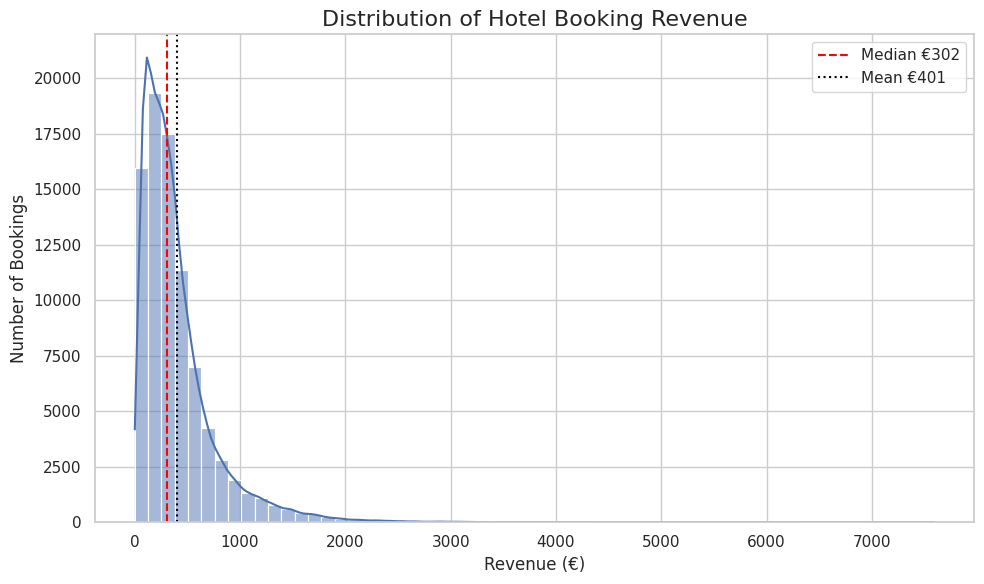

count    85501.00
mean       401.29
std        365.54
min          1.00
25%        160.00
50%        302.40
75%        507.50
max       7590.00
Name: revenue, dtype: float64

In [11]:
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='revenue', bins=60, kde=True)
plt.axvline(df['revenue'].median(), color='red', ls='--', label=f"Median €{df['revenue'].median():.0f}")
plt.axvline(df['revenue'].mean(), color='black', ls=':', label=f"Mean €{df['revenue'].mean():.0f}")
plt.title('Distribution of Hotel Booking Revenue', fontsize=16)
plt.xlabel('Revenue (€)'); plt.ylabel('Number of Bookings'); plt.legend()
plt.tight_layout(); plt.show()
df['revenue'].describe().round(2)

### Finding
Booking value is **right-skewed**. The median is about **€302** and the mean about **€401**, because a small number of long or expensive stays (up to €7,590 for a 69-night booking) pull the average up. Most bookings fall between about €160 and €510.

### Business Meaning
The "typical" booking is worth about €300. Averages overstate it, so the median is the safer number to quote for planning. The long tail of high-value bookings will also be the hardest for a linear model to predict.

## 6.3 Revenue by Hotel Type

booking_status  Cancelled (€M)  Not cancelled (€M)
hotel                                             
City Hotel                6.61               12.15
Resort Hotel              4.82               10.74


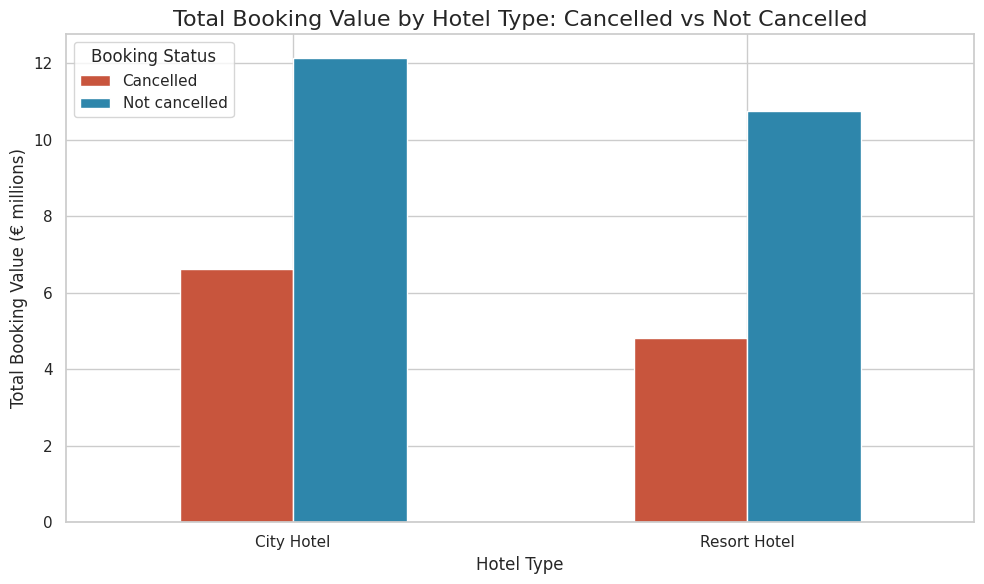


Average value per completed stay:
hotel
City Hotel      334.0
Resort Hotel    424.0
Name: revenue, dtype: float64


In [12]:
hotel_revenue_status = df.groupby(['hotel', 'booking_status'])['revenue'].sum().unstack(fill_value=0)
print((hotel_revenue_status / 1e6).round(2).rename(columns=lambda c: c + ' (€M)'))
(hotel_revenue_status / 1e6).plot(kind='bar', figsize=(10, 6), color=['#C8553D', '#2E86AB'])
plt.title('Total Booking Value by Hotel Type: Cancelled vs Not Cancelled', fontsize=16)
plt.xlabel('Hotel Type'); plt.ylabel('Total Booking Value (€ millions)'); plt.xticks(rotation=0)
plt.legend(title='Booking Status'); plt.tight_layout(); plt.show()
print('\nAverage value per completed stay:'); print(non_cancelled.groupby('hotel')['revenue'].mean().round(0))

### Finding
City Hotel realized **€12.15M** from completed stays and lost **€6.61M** of booking value to cancellations (35%). Resort Hotel realized **€10.74M** and lost **€4.82M** (31%). Across both hotels, **€11.43M of €34.31M (33.3%)** of booked value was cancelled.

Resort Hotel earns more per completed stay (about **€424 vs €334**) because its guests stay longer.

### Business Meaning
Cancellations are the single largest revenue leak, so managing them should be a priority for both properties. City Hotel drives volume, while Resort Hotel drives value per stay.

## 6.4 Revenue by Reserved Room Type

booking_status      Cancelled  Not cancelled
reserved_room_type                          
A                       372.0          294.0
B                       370.0          297.0
C                       942.0          732.0
D                       558.0          474.0
E                       697.0          562.0
F                       765.0          587.0
G                       981.0          701.0
H                       955.0          638.0

Completed stays per room type:
reserved_room_type
A    40710
D    11984
E     4296
F     1899
G     1216
B      653
C      598
H      334
L        4
Name: count, dtype: int64


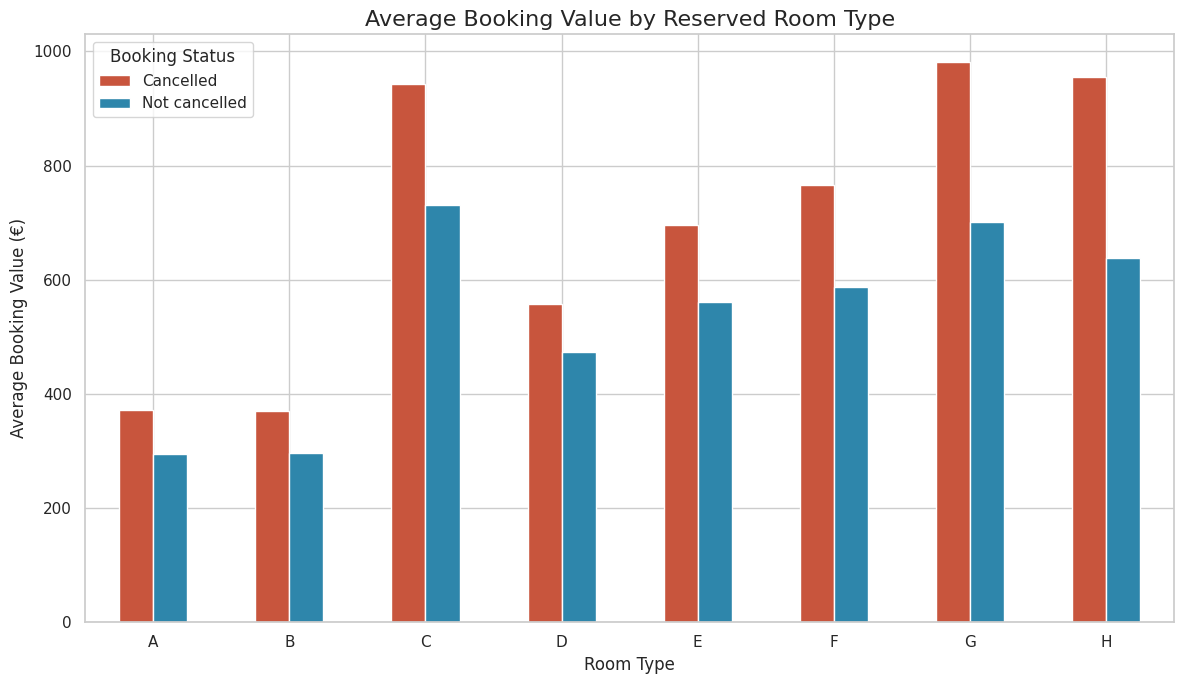

In [13]:
room = df[df['reserved_room_type'] != 'L']   # L has only 6 bookings
room_revenue = room.groupby(['reserved_room_type', 'booking_status'])['revenue'].mean().unstack(fill_value=0)
room_counts = non_cancelled['reserved_room_type'].value_counts()
print(room_revenue.round(0)); print('\nCompleted stays per room type:'); print(room_counts)
room_revenue.plot(kind='bar', figsize=(12, 7), color=['#C8553D', '#2E86AB'])
plt.title('Average Booking Value by Reserved Room Type', fontsize=16)
plt.xlabel('Room Type'); plt.ylabel('Average Booking Value (€)'); plt.xticks(rotation=0)
plt.legend(title='Booking Status'); plt.tight_layout(); plt.show()

### Finding
Room **A** is by far the most common room (more than **40,000 completed stays**) but has one of the lowest average values (about **€294**). Premium rooms **C, G and H** are worth about **€732, €701 and €638** per completed stay, which is 2–2.5× room A. Cancelled bookings show **higher** average values in every room type, so cancelled bookings tend to be longer or more expensive stays.

### Business Meaning
Upgrading even a small share of room-A guests to higher categories would lift revenue per booking without needing new demand. Because high-value bookings are also the ones that cancel, the hotels lose disproportionately more value per cancellation.

## 6.5 Average Revenue by Customer Type

                  mean  median   size
customer_type                        
Contract         527.0   425.0   3115
Transient        413.0   316.0  70536
Transient-Party  302.0   238.0  11339
Group            266.0   176.0    511


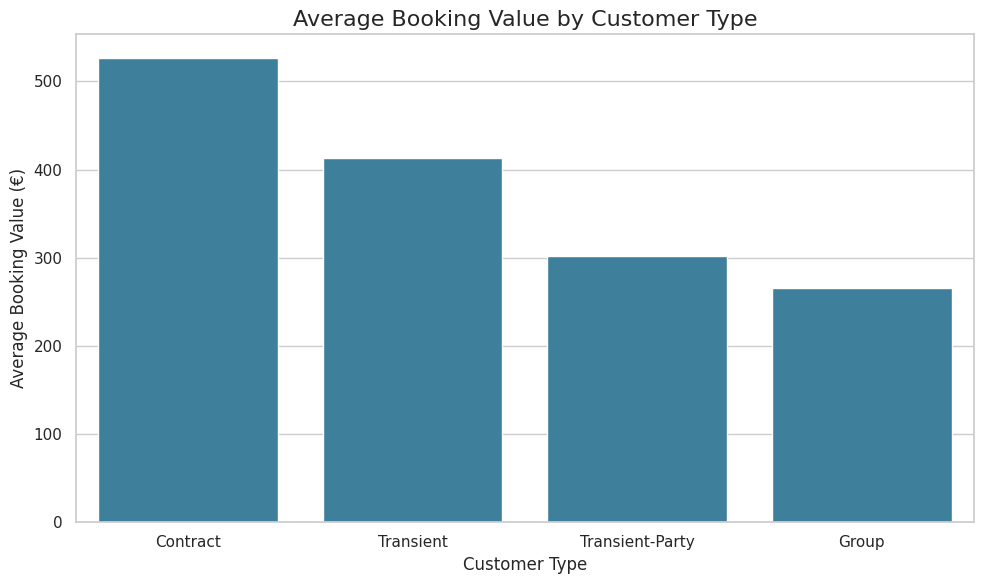

In [14]:
customer_revenue = df.groupby('customer_type')['revenue'].agg(['mean', 'median', 'size']).sort_values('mean', ascending=False)
print(customer_revenue.round(0))
plt.figure(figsize=(10, 6))
sns.barplot(x=customer_revenue.index, y=customer_revenue['mean'], color='#2E86AB')
plt.title('Average Booking Value by Customer Type', fontsize=16)
plt.xlabel('Customer Type'); plt.ylabel('Average Booking Value (€)')
plt.tight_layout(); plt.show()

### Finding
**Contract** customers have the highest average booking value (about **€527**), followed by **Transient** (**€413**), **Transient-Party** (**€302**) and **Group** (**€266**). Transient customers are by far the largest group by volume.

### Business Meaning
Contract customers are high-value, likely longer negotiated stays, and worth retaining through relationship management. Transient guests drive overall revenue through volume, so pricing for this segment has the biggest total impact.

## 6.6 Booking Activity by Month

                    bookings  years_covered  avg_adr  cancel_rate  \
arrival_date_month                                                  
January                 4571              2    71.91         0.22   
February                5954              2    76.47         0.23   
March                   7367              2    82.47         0.25   
April                   7783              2   105.20         0.31   
May                     8207              2   113.02         0.30   
June                    7651              2   121.52         0.31   
July                    9881              3   137.28         0.32   
August                 11044              3   151.91         0.33   
September               6538              2   114.61         0.25   
October                 6728              2    92.91         0.24   
November                4847              2    74.95         0.21   
December                4930              2    83.94         0.28   

                    bookings_per_

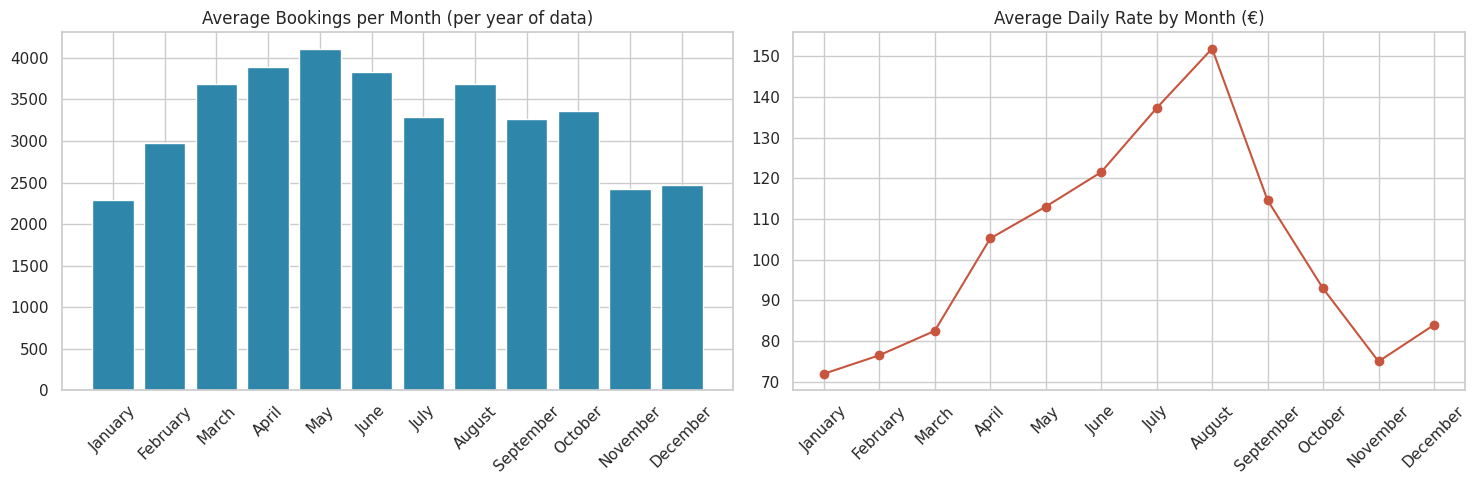

In [15]:
# The data covers Jul-2015 to Aug-2017: July and August appear in 3 years, every other month in 2.
# Raw counts would overstate summer, so we also show bookings per year of coverage.
monthly = df.groupby('arrival_date_month', observed=True).agg(
    bookings=('hotel', 'size'),
    years_covered=('arrival_date_year', 'nunique'),
    avg_adr=('adr', 'mean'),
    cancel_rate=('is_canceled', 'mean'))
monthly['bookings_per_year'] = monthly['bookings'] / monthly['years_covered']
monthly['completed_value_€M'] = non_cancelled.groupby('arrival_date_month', observed=True)['revenue'].sum() / 1e6
print(monthly.round(2))

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].bar(monthly.index.astype(str), monthly['bookings_per_year'], color='#2E86AB')
ax[0].set_title('Average Bookings per Month (per year of data)'); ax[0].tick_params(axis='x', rotation=45)
ax[1].plot(monthly.index.astype(str), monthly['avg_adr'], marker='o', color='#C8553D')
ax[1].set_title('Average Daily Rate by Month (€)'); ax[1].tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()

### Finding
August (11,044) and July (9,881) have the most bookings in **raw counts**, but they appear in three years of data instead of two. **Per year**, booking volume is highest in **May (≈4,100), April and June**. August is still the highest-value month: ADR peaks at about **€152** (vs about €72 in January), and August generated **€4.55M** from completed stays. November to January is the low season. July and August also have the highest cancellation rates (**≈32%**).

### Business Meaning
Summer combines high volume, the highest rates and the highest cancellation exposure, so pricing and cancellation control matter most there. Spring has strong volume at mid-level rates and is an opportunity to raise prices or upsell. Winter needs demand-stimulating offers.

## 6.7 Market Segment Analysis
### 6.7.1 Booking Volume by Market Segment

booking_status  Cancelled  Not cancelled  cancel_rate_%
market_segment                                         
Undefined               2              0          100.0
Online TA           18202          33005           35.5
Groups               1314           3400           27.9
Aviation               44            178           19.8
Offline TA/TO        2028          11590           14.9
Direct               1707           9838           14.8
Corporate             505           3626           12.2
Complementary           5             57            8.1


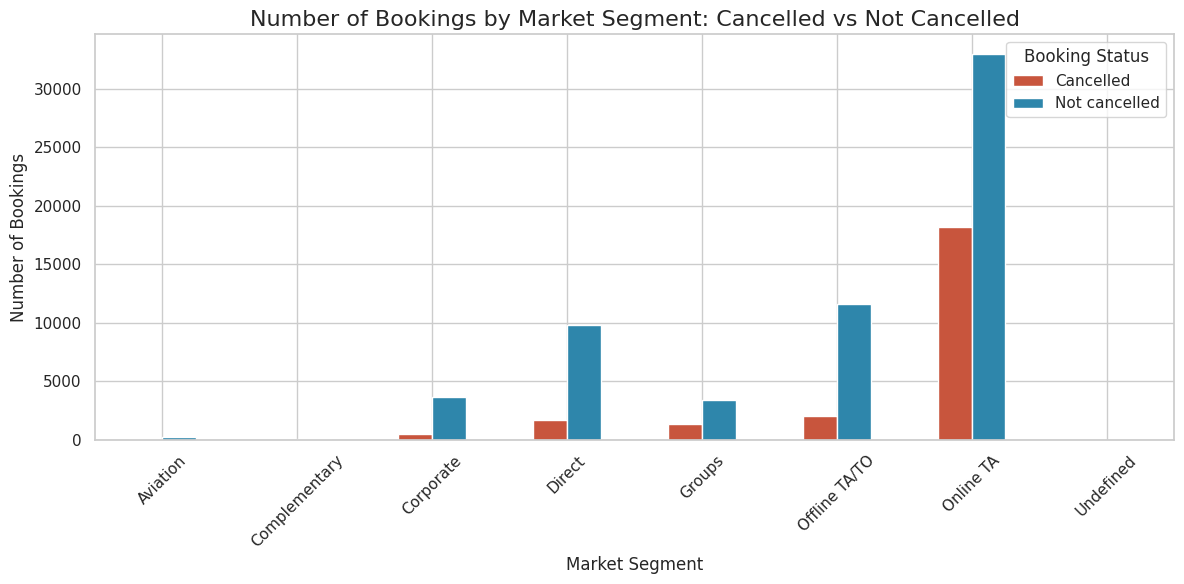

In [16]:
segment_counts = df.groupby(['market_segment', 'booking_status']).size().unstack(fill_value=0)
segment_counts['cancel_rate_%'] = (segment_counts['Cancelled'] / segment_counts.sum(axis=1) * 100).round(1)
print(segment_counts.sort_values('cancel_rate_%', ascending=False))
segment_counts[['Cancelled', 'Not cancelled']].plot(kind='bar', figsize=(12, 6), color=['#C8553D', '#2E86AB'])
plt.title('Number of Bookings by Market Segment: Cancelled vs Not Cancelled', fontsize=16)
plt.xlabel('Market Segment'); plt.ylabel('Number of Bookings'); plt.xticks(rotation=45)
plt.legend(title='Booking Status'); plt.tight_layout(); plt.show()

### Finding
**Online TA** dominates volume (**51,207 bookings, 60%**) and has the highest cancellation rate of the major segments (**35.5%**, or 18,202 cancellations). Direct and Offline TA/TO bookings cancel at about **15%**, and Corporate at about **12%**.

### Business Meaning
Online travel agencies bring demand but much less reliable demand. Growing Direct bookings would make occupancy more predictable. Online TA bookings may need stricter cancellation terms, especially in peak months.

### 6.7.2 Total Booking Value by Market Segment

booking_status  Cancelled  Not cancelled
market_segment                          
Aviation             0.01           0.07
Complementary        0.00           0.00
Corporate            0.11           0.48
Direct               0.92           3.88
Groups               0.31           0.92
Offline TA/TO        0.81           4.59
Online TA            9.25          12.93
Undefined            0.00           0.00


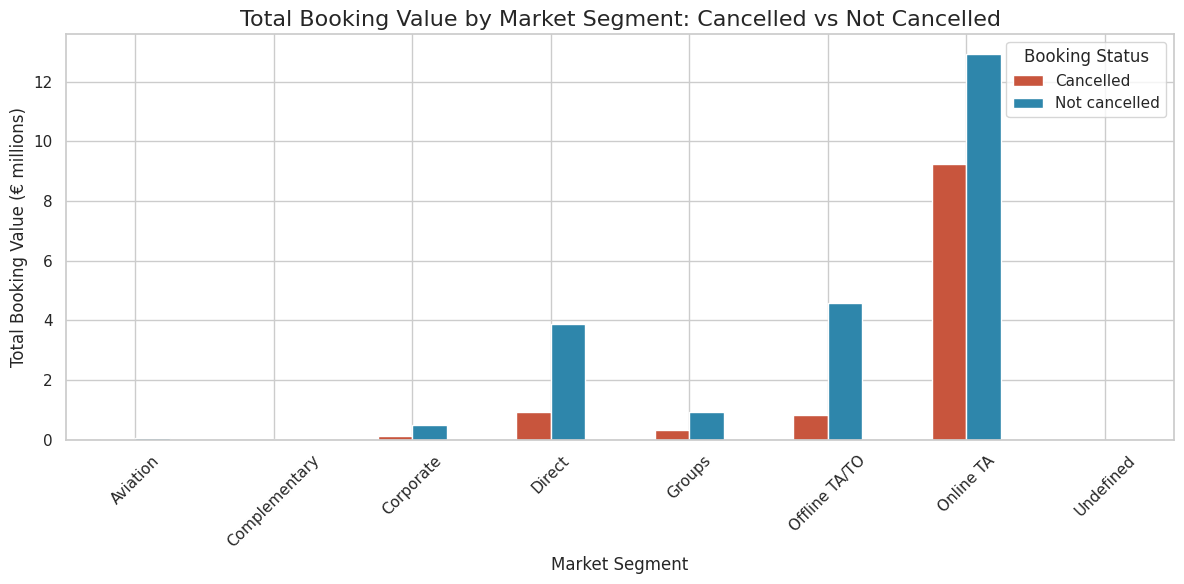

In [17]:
market_revenue_status = df.groupby(['market_segment', 'booking_status'])['revenue'].sum().unstack(fill_value=0)
print((market_revenue_status / 1e6).round(2))
(market_revenue_status / 1e6).plot(kind='bar', figsize=(12, 6), color=['#C8553D', '#2E86AB'])
plt.title('Total Booking Value by Market Segment: Cancelled vs Not Cancelled', fontsize=16)
plt.xlabel('Market Segment'); plt.ylabel('Total Booking Value (€ millions)'); plt.xticks(rotation=45)
plt.legend(title='Booking Status'); plt.tight_layout(); plt.show()

### Finding
Online TA produced **€12.93M** from completed stays, but **€9.25M** of its booking value was cancelled. That is **81% of all cancelled value** across segments. Direct produced **€3.88M** with only **€0.92M** cancelled.

### Business Meaning
Ranking channels by booked value alone overstates Online TA. Channel decisions should use **retained (completed) revenue**, net of commission. Direct bookings earn similar value per booking with far less cancellation and no OTA commission.

## 6.8 Length of Stay vs Revenue

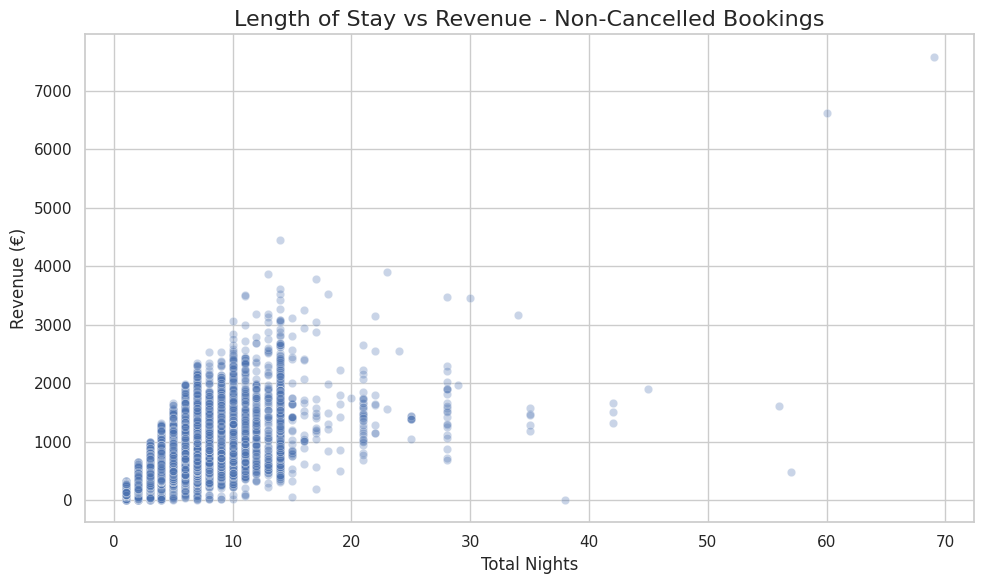

Correlation: 0.751


In [18]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=non_cancelled, x='total_nights', y='revenue', alpha=0.3)
plt.title('Length of Stay vs Revenue - Non-Cancelled Bookings', fontsize=16)
plt.xlabel('Total Nights'); plt.ylabel('Revenue (€)')
plt.tight_layout(); plt.show()
print('Correlation:', round(non_cancelled['total_nights'].corr(non_cancelled['revenue']), 3))

### Finding
Revenue rises clearly with the number of nights (correlation **0.75**, the strongest of any variable). The spread widens for longer stays, because nightly rates vary more across long bookings. A handful of very long stays (more than 21 nights, up to 69) sit far from the rest.

### Business Meaning
Length of stay is the biggest lever on booking value. Multi-night packages and minimum-stay rules in peak periods directly raise revenue per booking. The widening spread means prediction errors will grow for long stays.

## 6.9 Lead Time vs Revenue

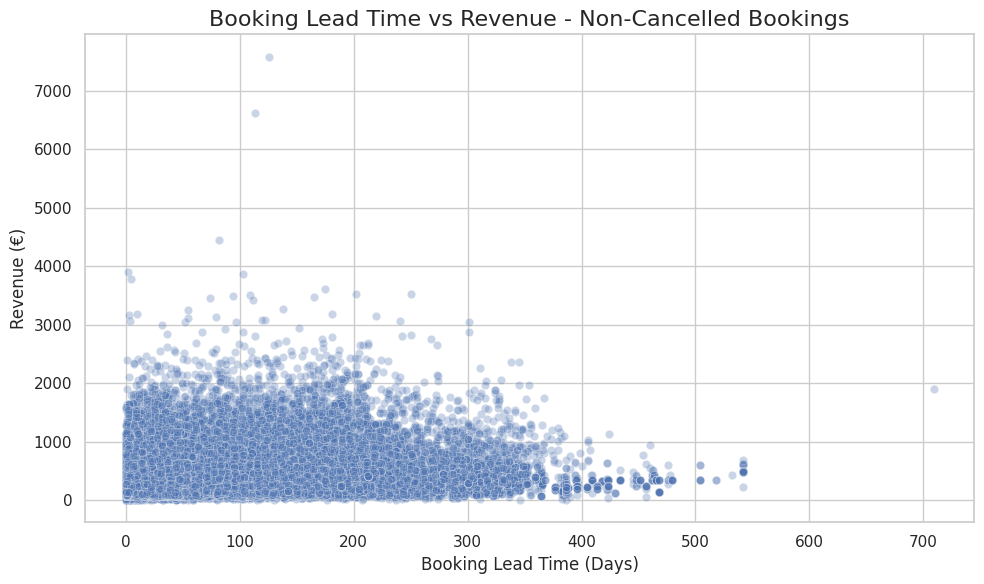

Correlation: 0.286

Cancellation rate by lead time (days):
lead_time
0-7         8.4
8-30       25.6
31-90      32.2
91-180     35.1
181-365    39.9
365+       41.8
Name: is_canceled, dtype: float64


In [19]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=non_cancelled, x='lead_time', y='revenue', alpha=0.3)
plt.title('Booking Lead Time vs Revenue - Non-Cancelled Bookings', fontsize=16)
plt.xlabel('Booking Lead Time (Days)'); plt.ylabel('Revenue (€)')
plt.tight_layout(); plt.show()
print('Correlation:', round(non_cancelled['lead_time'].corr(non_cancelled['revenue']), 3))
lt = pd.cut(df['lead_time'], [-1, 7, 30, 90, 180, 365, 800], labels=['0-7', '8-30', '31-90', '91-180', '181-365', '365+'])
print('\nCancellation rate by lead time (days):'); print(df.groupby(lt, observed=True)['is_canceled'].mean().mul(100).round(1))

### Finding
Lead time has only a **weak positive** relationship with revenue (correlation ≈ **0.29**). Bookings made further ahead tend to be slightly longer stays, but the cloud is wide. Lead time matters much more for **cancellation**: about **8%** of bookings made within a week cancel, compared with about **40%** of bookings made more than six months ahead.

### Business Meaning
Lead time is a weak predictor of how much a booking is worth but a strong signal of cancellation risk. Deposits or partial prepayment for long-lead bookings would protect revenue.

## 6.10 Correlation Analysis

revenue                           1.000
total_nights                      0.751
stays_in_week_nights              0.711
stays_in_weekend_nights           0.583
adr                               0.543
lead_time                         0.286
adults                            0.269
children                          0.179
total_of_special_requests         0.162
booking_changes                   0.077
babies                            0.036
required_car_parking_spaces       0.025
days_in_waiting_list             -0.022
previous_cancellations           -0.038
previous_bookings_not_canceled   -0.076
Name: revenue, dtype: float64


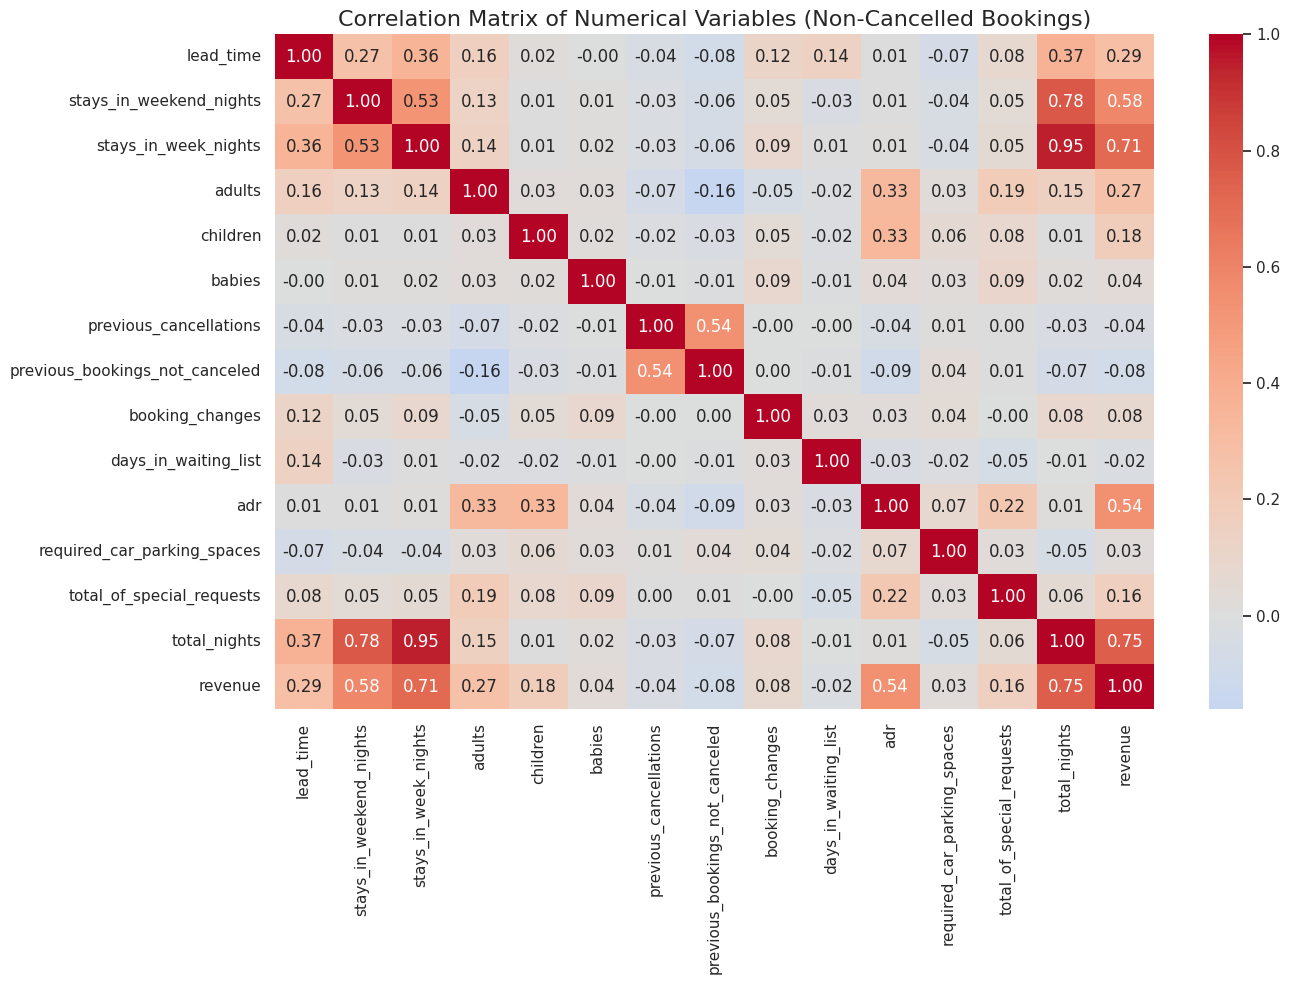

In [20]:
numeric_columns = ['lead_time', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies',
                   'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'days_in_waiting_list',
                   'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'total_nights', 'revenue']
correlation_matrix = non_cancelled[numeric_columns].corr()
print(correlation_matrix['revenue'].sort_values(ascending=False).round(3))
plt.figure(figsize=(14, 10))
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Matrix of Numerical Variables (Non-Cancelled Bookings)', fontsize=16)
plt.tight_layout(); plt.show()

### Finding
`total_nights` (0.75) and its parts, `stays_in_week_nights` (0.71) and `stays_in_weekend_nights` (0.58), have the strongest relationships with revenue, followed by `adr` (0.54). `lead_time` (0.29), `adults` (0.27), `children` (0.18) and special requests (0.16) are weaker. Previous cancellations and waiting-list days are close to zero.

Two cautions for modelling:
1. **`adr` must not be used as a model input.** Revenue is calculated as ADR × nights, so including it would let the model partly "see" the answer (target leakage).
2. `total_nights` is the sum of weekday and weekend nights, so we use **only `total_nights`** to avoid duplicated information (multicollinearity).

### Business Meaning
How long guests stay matters more for booking value than any guest or booking-behaviour attribute. Revenue strategy should focus on stay length, room category and season rather than on lead time or party size.

# 7. SQL Analysis
*SQL analysis: Jacinta Syokau, Stephen Bonu.* The cleaned data is loaded once into a SQLite database file (`hotel.db`), and every query uses this single connection. The same queries are in `group3_hotel_analysis.sql`.

In [21]:
conn = sqlite3.connect('hotel.db')
df.assign(arrival_date_month=df['arrival_date_month'].astype(str)).to_sql('hotel_booking', conn, index=False, if_exists='replace')
q = lambda sql: pd.read_sql(sql, conn)
q('SELECT COUNT(*) AS n_bookings FROM hotel_booking')

,n_bookings
0,85501


### 7.1 Which room types generate the highest average revenue?

In [22]:
q('''
SELECT reserved_room_type,
       COUNT(*)                                                   AS n_bookings,
       ROUND(AVG(revenue), 2)                                     AS avg_booking_value,
       ROUND(AVG(CASE WHEN is_canceled = 0 THEN revenue END), 2)  AS avg_completed_value
FROM hotel_booking
GROUP BY reserved_room_type
HAVING COUNT(*) >= 100
ORDER BY avg_completed_value DESC;
''')

,reserved_room_type,n_bookings,avg_booking_value,avg_completed_value
0,C,891,800.81,731.65
1,G,1932,804.58,700.85
2,H,568,768.72,638.15
3,F,2743,642.01,587.24
4,E,5932,598.94,561.76
5,D,17206,499.66,474.21
6,B,968,320.96,297.20
7,A,55255,314.61,294.16


### Finding
Room **C** has the highest average value per completed stay (about **€732**), followed by **G (€701)** and **H (€638)**. Including cancelled bookings, G and C are both about **€800**. Room **A** is the lowest at about **€294–315** but accounts for 55,255 bookings.

### Business Meaning
Premium rooms are worth more than twice room A per booking, which makes them a clear upsell target. *Room L (6 bookings) is excluded with `HAVING COUNT(*) >= 100` because its average is not reliable.*

### 7.2 Which months have the highest booking activity?

In [23]:
q('''
SELECT arrival_date_month,
       COUNT(*)                                                         AS n_bookings,
       COUNT(DISTINCT arrival_date_year)                                AS years_covered,
       ROUND(COUNT(*) * 1.0 / COUNT(DISTINCT arrival_date_year), 0)     AS bookings_per_year,
       ROUND(AVG(adr), 2)                                               AS avg_adr,
       ROUND(SUM(CASE WHEN is_canceled = 0 THEN revenue ELSE 0 END), 0) AS completed_value
FROM hotel_booking
GROUP BY arrival_date_month
ORDER BY n_bookings DESC;
''')

,arrival_date_month,n_bookings,years_covered,bookings_per_year,avg_adr,completed_value
0,August,11044,3,3681.0,151.91,4552767.0
1,July,9881,3,3294.0,137.28,3775533.0
2,May,8207,2,4104.0,113.02,2057470.0
3,April,7783,2,3892.0,105.20,1804150.0
4,June,7651,2,3826.0,121.52,2296399.0
5,March,7367,2,3684.0,82.47,1415693.0
6,October,6728,2,3364.0,92.91,1476095.0
7,September,6538,2,3269.0,114.61,1968663.0
8,February,5954,2,2977.0,76.47,1024915.0
9,December,4930,2,2465.0,83.94,913721.0


### Finding
In raw counts, **August (11,044)** and **July (9,881)** are the busiest months, and August has the highest ADR (**€152**) and completed value (**€4.55M**). After adjusting for data coverage (`bookings_per_year`), **May, April and June** have the most bookings per year. November to January is the quietest period.

### Business Meaning
Summer is the highest-value period. Spring is the highest-volume period per year, so prices there may have room to rise. Seasonal staffing and pricing should follow both patterns.

### 7.3 What is the average revenue for different customer segments?

In [24]:
q('''
SELECT market_segment,
       COUNT(*)                                                   AS n_bookings,
       ROUND(AVG(revenue), 2)                                     AS avg_booking_value,
       ROUND(AVG(CASE WHEN is_canceled = 0 THEN revenue END), 2)  AS avg_completed_value
FROM hotel_booking
WHERE market_segment <> 'Undefined'
GROUP BY market_segment
ORDER BY avg_booking_value DESC;
''')

,market_segment,n_bookings,avg_booking_value,avg_completed_value
0,Online TA,51207,433.27,391.89
1,Direct,11545,415.96,394.61
2,Offline TA/TO,13618,397.05,396.22
3,Aviation,222,374.02,387.46
4,Groups,4714,261.83,270.40
5,Corporate,4131,143.55,133.09
6,Complementary,62,81.85,84.29


### Finding
**Online TA (€433)**, **Direct (€416)** and **Offline TA/TO (€397)** have the highest average booking value. **Corporate (€144)** and **Complementary (€82)** are the lowest.

### Business Meaning
The three main leisure channels bring similar value per booking. Their difference is reliability and cost: cancellation rates and commission.

### 7.4 Which market segments generate the most total revenue?

In [25]:
q('''
SELECT market_segment,
       COUNT(*)                                                         AS n_bookings,
       ROUND(SUM(revenue), 0)                                           AS total_booking_value,
       ROUND(SUM(CASE WHEN is_canceled = 0 THEN revenue ELSE 0 END), 0) AS completed_value,
       ROUND(100.0 * SUM(CASE WHEN is_canceled = 0 THEN revenue ELSE 0 END) / SUM(revenue), 1) AS pct_value_retained
FROM hotel_booking
GROUP BY market_segment
ORDER BY completed_value DESC;
''')

,market_segment,n_bookings,total_booking_value,completed_value,pct_value_retained
0,Online TA,51207,22186297.0,12934211.0,58.3
1,Offline TA/TO,13618,5406980.0,4592184.0,84.9
2,Direct,11545,4802252.0,3882220.0,80.8
3,Groups,4714,1234286.0,919346.0,74.5
4,Corporate,4131,592998.0,482583.0,81.4
5,Aviation,222,83033.0,68968.0,83.1
6,Complementary,62,5075.0,4805.0,94.7
7,Undefined,2,48.0,0.0,0.0


### Finding
Online TA generates the most completed revenue (**€12.93M**) but retains only about **58%** of its booked value. Direct retains about **81%** and Offline TA/TO about **85%**.

### Business Meaning
Retained revenue gives a truer picture of channel value than booked value.

### 7.5 What is the cancellation rate by market segment?

In [26]:
q('''
SELECT market_segment,
       COUNT(*)                          AS n_bookings,
       SUM(is_canceled)                  AS n_cancelled,
       ROUND(AVG(is_canceled) * 100, 1)  AS cancellation_rate_pct
FROM hotel_booking
WHERE market_segment <> 'Undefined'
GROUP BY market_segment
ORDER BY cancellation_rate_pct DESC;
''')

,market_segment,n_bookings,n_cancelled,cancellation_rate_pct
0,Online TA,51207,18202,35.5
1,Groups,4714,1314,27.9
2,Aviation,222,44,19.8
3,Offline TA/TO,13618,2028,14.9
4,Direct,11545,1707,14.8
5,Corporate,4131,505,12.2
6,Complementary,62,5,8.1


### Finding
**Online TA** has the highest cancellation rate (**35.5%**), followed by Groups (27.9%) and Aviation (19.8%). Direct and Offline TA/TO are both about **15%**.

### Business Meaning
This query provides the evidence behind the report's and deck's "Online TA 35.5% vs Direct/Offline 15%" claim.

### 7.6 What is the overall cancellation rate?

In [27]:
q('''
SELECT COUNT(*)                                                  AS n_bookings,
       SUM(is_canceled)                                          AS n_cancelled,
       ROUND(AVG(is_canceled) * 100, 2)                          AS cancellation_rate_pct,
       ROUND(SUM(CASE WHEN is_canceled = 1 THEN revenue END), 0) AS cancelled_value
FROM hotel_booking;
''')

,n_bookings,n_cancelled,cancellation_rate_pct,cancelled_value
0,85501,23807,27.84,11426652.0


### Finding
**23,807 of 85,501 bookings (27.84%)** were cancelled, representing about **€11.43M** in booking value.

### Business Meaning
More than one in four bookings never becomes a stay. Cancellation management is the biggest single revenue opportunity.

### 7.7 What is the average length of stay?

In [28]:
q('''
SELECT hotel,
       ROUND(AVG(total_nights), 2) AS avg_length_of_stay
FROM hotel_booking
WHERE is_canceled = 0
GROUP BY hotel
UNION ALL
SELECT 'All hotels', ROUND(AVG(total_nights), 2) FROM hotel_booking WHERE is_canceled = 0;
''')

,hotel,avg_length_of_stay
0,City Hotel,3.03
1,Resort Hotel,4.27
2,All hotels,3.54


### Finding
Completed stays last **3.54 nights** on average: about **3.0** at City Hotel and **4.3** at Resort Hotel.

### Business Meaning
Resort guests stay longer, which explains Resort Hotel's higher value per booking despite lower nightly rates.

### 7.8 Which room types are booked most frequently?

In [29]:
q('''
SELECT reserved_room_type,
       COUNT(*)                                            AS n_bookings,
       ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM hotel_booking), 1) AS share_pct
FROM hotel_booking
GROUP BY reserved_room_type
ORDER BY n_bookings DESC;
''')

,reserved_room_type,n_bookings,share_pct
0,A,55255,64.6
1,D,17206,20.1
2,E,5932,6.9
3,F,2743,3.2
4,G,1932,2.3
5,B,968,1.1
6,C,891,1.0
7,H,568,0.7
8,L,6,0.0


### Finding
Room **A** accounts for **64.6%** of bookings and room **D** for **20.1%**. Premium rooms C, G and H together account for less than 4%.

### Business Meaning
The booking mix is concentrated in the lowest-value room, which is the basis for the room-upgrade recommendation.

# 8. Feature Engineering & Preprocessing
*Modelling: Shalom Okanlawon, Dunmiye Bunmi, Nwoba Anayo.* The feature set below is the modelling team's selection. It is used for the official model.

**Target (y):** `revenue` (booking value = ADR × nights) for all bookings.

**Features (X):** 16 booking attributes known at the time of booking:
- Numeric (8): `lead_time`, `arrival_date_year`, `stays_in_weekend_nights`, `stays_in_week_nights`, `adults`, `children`, `booking_changes`, `total_of_special_requests`
- Categorical (8, one-hot encoded): `hotel`, `arrival_date_month`, `meal`, `market_segment`, `distribution_channel`, `reserved_room_type`, `deposit_type`, `customer_type`

`arrival_date_year` captures the year-on-year price trend. It also makes the intercept a large negative number (around −103,000), because the year values are near 2016. The intercept has no real-world meaning on its own.

**Excluded on purpose:**

| Column | Reason |
|---|---|
| `adr` | Revenue is calculated from ADR, so it would leak the answer |
| `total_nights` | Equal to weekend + week nights, which are already included separately |
| `reservation_status`, `reservation_status_date`, `assigned_room_type`, `is_canceled` | Only known after arrival (leakage) |
| `country` | Too many categories; also avoids pricing by nationality |

**Data fixes before modelling:**
- Meal `Undefined` is recoded as `SC` (they mean the same thing per the dataset documentation).
- Rows with an `Undefined` market segment (2) or distribution channel (5) are removed. Otherwise they create dummy columns estimated from 1–2 rows.
- Bookings with 0 adults (244, including all 31 bookings with no guests at all) are removed.
- The data is **encoded before splitting**, so train and test always share the same columns.

In [30]:
model_df = df.copy()
model_df['meal'] = model_df['meal'].replace('Undefined', 'SC')                 # Undefined = SC (no meal)
model_df = model_df[(model_df['market_segment'] != 'Undefined') &
                    (model_df['distribution_channel'] != 'Undefined') &
                    (model_df['adults'] > 0)]
model_df['arrival_date_month'] = model_df['arrival_date_month'].astype(str)
print(f'Modelling rows: {len(model_df):,} (removed {len(df) - len(model_df)} unusual rows)')

numeric_features = ['lead_time', 'arrival_date_year', 'stays_in_weekend_nights', 'stays_in_week_nights',
                    'adults', 'children', 'booking_changes', 'total_of_special_requests']
categorical_features = ['hotel', 'arrival_date_month', 'meal', 'market_segment', 'distribution_channel',
                        'reserved_room_type', 'deposit_type', 'customer_type']

X = pd.get_dummies(model_df[numeric_features + categorical_features], columns=categorical_features, drop_first=True, dtype=int)
y = model_df['revenue']
print('X shape:', X.shape)

def add_interactions(X_in):
    # Interaction terms used by the improved model in Section 10.4
    out = X_in.copy()
    for c in [c for c in X_in.columns if c.startswith('arrival_date_month_')]:
        out[f'resort_x_{c}'] = X_in[c] * X_in['hotel_Resort Hotel']        # seasonality differs by hotel
    for c in [c for c in X_in.columns if c.startswith('reserved_room_type_')]:
        out[f'nights_x_{c}'] = X_in[c] * (X_in['stays_in_weekend_nights'] + X_in['stays_in_week_nights'])  # room premium accrues per night
    return out

Modelling rows: 85,252 (removed 249 unusual rows)
X shape: (85252, 45)


**One-hot encoding** turns each category into 0/1 columns so linear regression can use it. `drop_first=True` drops one category per variable, which becomes the **reference category** (April for month, room A, BB meal, City Hotel, Aviation segment, Corporate channel, No Deposit, Contract customer). Each coefficient is then read as "difference versus the reference".

In [31]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('X_train:', X_train.shape, '| X_test:', X_test.shape)
print('y_train:', y_train.shape, '| y_test:', y_test.shape)

X_train: (68201, 45) | X_test: (17051, 45)
y_train: (68201,) | y_test: (17051,)


### Why a train-test split is necessary
The model learns from the **training set (80%)** and is scored on the **test set (20%)**, which it never sees during training. If we scored it on the same data it learned from, it could memorize noise and look better than it really is (**overfitting**). The test score is our estimate of how well the model will predict **new** bookings. `random_state=42` makes the split reproducible.

# 9. Linear Regression Model

## Model Creation and Training

In [32]:
model = LinearRegression()
model.fit(X_train, y_train)
print(f'Intercept: €{model.intercept_:.2f} | number of coefficients: {len(model.coef_)}')

Intercept: €-103371.77 | number of coefficients: 45


**What the model is doing:** Linear regression finds one weight (coefficient) per feature so that

`predicted revenue = intercept + coef₁ × feature₁ + coef₂ × feature₂ + …`

is as close as possible to the actual revenue. It minimizes the squared prediction errors on the training data. Each coefficient is the change in predicted revenue for a one-unit change in that feature, holding the other features constant.

The intercept is about **−€103,372**. This is not a real revenue value: it offsets `arrival_date_year` × its coefficient (≈ 2016 × €51), so predictions land in the normal range.

## Prediction

In [33]:
y_pred = model.predict(X_test)
pd.DataFrame({'actual': y_test.values[:10], 'predicted': y_pred[:10].round(2)})

,actual,predicted
0,277.20,357.02
1,86.85,72.58
2,630.00,419.13
3,558.00,456.27
4,772.00,640.24
5,230.00,214.87
6,960.00,845.54
7,129.00,111.27
8,492.00,433.94
9,315.90,270.51


# 10. Model Evaluation

In [34]:
r2   = r2_score(y_test, y_pred)
mae  = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))   # RMSE = square root of MSE (do NOT take another square root)
r2_train = r2_score(y_train, model.predict(X_train))

baseline_pred = DummyRegressor(strategy='mean').fit(X_train, y_train).predict(X_test)
baseline_mae = mean_absolute_error(y_test, baseline_pred)
cv_r2 = cross_val_score(LinearRegression(), X_train, y_train, cv=5, scoring='r2')

results = pd.DataFrame({
    'Metric': ['R² (test)', 'R² (train)', 'R² (5-fold CV mean)', 'MAE (€)', 'RMSE (€)', 'Baseline MAE (€)', 'Error reduction vs baseline'],
    'Value':  [r2, r2_train, cv_r2.mean(), mae, rmse, baseline_mae, 1 - mae / baseline_mae]})
results['Value'] = results['Value'].round(3)
results

,Metric,Value
0,R² (test),0.762
1,R² (train),0.758
2,R² (5-fold CV mean),0.758
3,MAE (€),115.131
4,RMSE (€),177.890
5,Baseline MAE (€),250.983
6,Error reduction vs baseline,0.541


In [35]:
# Comparison: the original 5-feature model vs the full model
X5 = model_df[['total_nights', 'lead_time', 'adults', 'children', 'babies']]   # the group's original 5-feature model
X5_tr, X5_te, y5_tr, y5_te = train_test_split(X5, y, test_size=0.2, random_state=42)
p5 = LinearRegression().fit(X5_tr, y5_tr).predict(X5_te)
pd.DataFrame({
    'Model': ['Original 5 numeric features', 'Model 2: modelling team features (16)'],
    'Test R²': [r2_score(y5_te, p5), r2],
    'MAE (€)': [mean_absolute_error(y5_te, p5), mae],
    'RMSE (€)': [np.sqrt(mean_squared_error(y5_te, p5)), rmse]}).round(3)

,Model,Test R²,MAE (€),RMSE (€)
0,Original 5 numeric features,0.635,137.208,220.309
1,Model 2: modelling team features (16),0.762,115.131,177.890


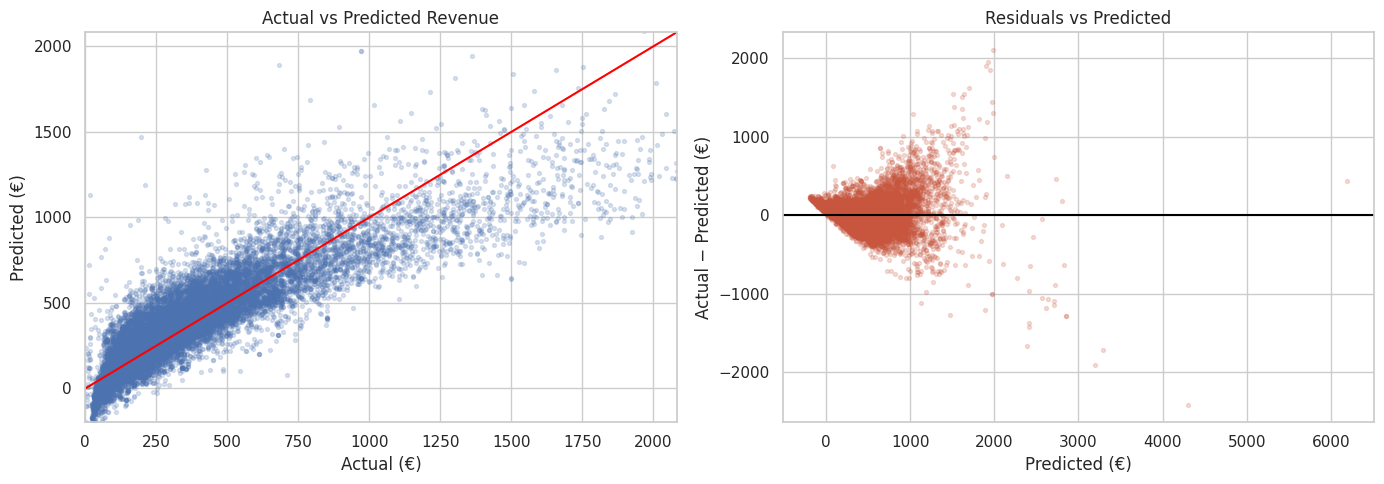

Negative predictions: 855 of 17,051 (5.0%)


In [36]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].scatter(y_test, y_pred, alpha=0.2, s=8)
lim = [0, np.percentile(y_test, 99.5)]
ax[0].plot(lim, lim, color='red'); ax[0].set_xlim(lim); ax[0].set_ylim(min(0, y_pred.min()), lim[1])
ax[0].set_title('Actual vs Predicted Revenue'); ax[0].set_xlabel('Actual (€)'); ax[0].set_ylabel('Predicted (€)')
residuals = y_test - y_pred
ax[1].scatter(y_pred, residuals, alpha=0.2, s=8, color='#C8553D'); ax[1].axhline(0, color='black')
ax[1].set_title('Residuals vs Predicted'); ax[1].set_xlabel('Predicted (€)'); ax[1].set_ylabel('Actual − Predicted (€)')
plt.tight_layout(); plt.show()
print(f'Negative predictions: {(y_pred < 0).sum():,} of {len(y_pred):,} ({(y_pred < 0).mean():.1%})')

### What the scores mean
- **R² ≈ 0.76**: Model 2 explains about **76% of the variation** in booking value. 1.0 would be perfect and 0 would be no better than always predicting the average. This is the regression equivalent of an "accuracy score".
- **MAE ≈ €115**: on average, predictions are about €115 away from the actual booking value. A naive model that always predicts the average is off by about €251, so the model **cuts the error by about 54%**.
- **RMSE ≈ €178**: like MAE, but it penalizes large misses more. RMSE being well above MAE shows that a few large errors exist, mainly on high-value bookings.
- **Train R² ≈ test R² ≈ CV R²**: the model performs the same on unseen data, so it is **not overfitting**.
- The modelling team's 16 features raise R² from **0.64** (the original 5 numeric features) to **0.76**. Section 10.4 adds interaction terms to reach the **official model (R² ≈ 0.84)**.

### Is the model performing well?
For a simple linear model that deliberately does **not** use the room rate (ADR), this is **good** performance. It captures the main revenue drivers well enough to support analysis and decision-making.

### What affects the score
1. **Long, high-value stays:** errors grow with stay length (the fan shape in the residual plot).
2. **Negative predictions:** about 5% of predictions are below €0, which is impossible for revenue. A linear model has no lower bound.
3. **Linearity assumption:** real effects interact (for example, summer × resort), and linear regression only adds effects together.
4. **Cancelled bookings:** these are included as booking value. Whether a booking will actually be realized is a separate question.
5. **Missing information:** competitor prices, events and promotions are not in the data.

## 10.1 Statistical Significance
Scikit-learn gives predictions; `statsmodels` gives the same coefficients with **p-values and 95% confidence intervals**, which show whether each effect is statistically distinguishable from zero.

In [37]:
ols = sm.OLS(y_train.astype(float), sm.add_constant(X_train.astype(float))).fit()
print(f'R²: {ols.rsquared:.3f} | Adjusted R²: {ols.rsquared_adj:.3f} | Features: {X_train.shape[1]} | Training rows: {len(X_train):,}')
sig = pd.DataFrame({'coef_€': ols.params, 'p_value': ols.pvalues,
                    'ci_low': ols.conf_int()[0], 'ci_high': ols.conf_int()[1]}).drop('const')
sig['significant (p<0.05)'] = sig['p_value'] < 0.05
print(f"Significant features: {sig['significant (p<0.05)'].sum()} of {len(sig)}")
print('\nNot significant:', sig.index[~sig['significant (p<0.05)']].tolist())
sig.reindex(sig['coef_€'].abs().sort_values(ascending=False).index).head(15).round(3)

R²: 0.758 | Adjusted R²: 0.758 | Features: 45 | Training rows: 68,201
Significant features: 41 of 45

Not significant: ['market_segment_Corporate', 'distribution_channel_Direct', 'distribution_channel_TA/TO', 'reserved_room_type_L']


,coef_€,p_value,ci_low,ci_high,significant (p<0.05)
meal_FB,326.457,0.0,305.254,347.661,True
reserved_room_type_H,286.071,0.0,268.361,303.782,True
reserved_room_type_G,278.614,0.0,267.888,289.340,True
arrival_date_month_August,220.621,0.0,214.626,226.616,True
reserved_room_type_C,194.533,0.0,179.956,209.111,True
reserved_room_type_F,178.140,0.0,169.273,187.006,True
market_segment_Complementary,-164.787,0.0,-223.203,-106.371,True
arrival_date_month_July,161.550,0.0,155.460,167.641,True
meal_HB,153.302,0.0,148.611,157.993,True
reserved_room_type_E,108.103,0.0,102.412,113.795,True


### Finding
Adjusted R² (0.758) equals R², so the 45 features are not inflating the score. **41 of 45** features are significant (p < 0.05). The 4 that are not:
- **`reserved_room_type_L`** (p ≈ 0.72): with only 6 bookings its estimate is too uncertain to trust, which is why L was excluded from the room charts.
- **`market_segment_Corporate`**: no different in value from the Aviation reference.
- **`distribution_channel_Direct`** and **`distribution_channel_TA/TO`**: once the market segment is known, the distribution channel adds no extra information about value. The two variables overlap heavily.

### Business Meaning
Online TA and Direct bookings carry almost **identical** value in the model (≈ +€41 each versus the reference). The channels differ in **reliability** (35.5% vs 14.8% cancellation), not in what a booking is worth. This strengthens the case for shifting volume to Direct: same value, lower risk, no commission.

## 10.2 Regression Assumptions

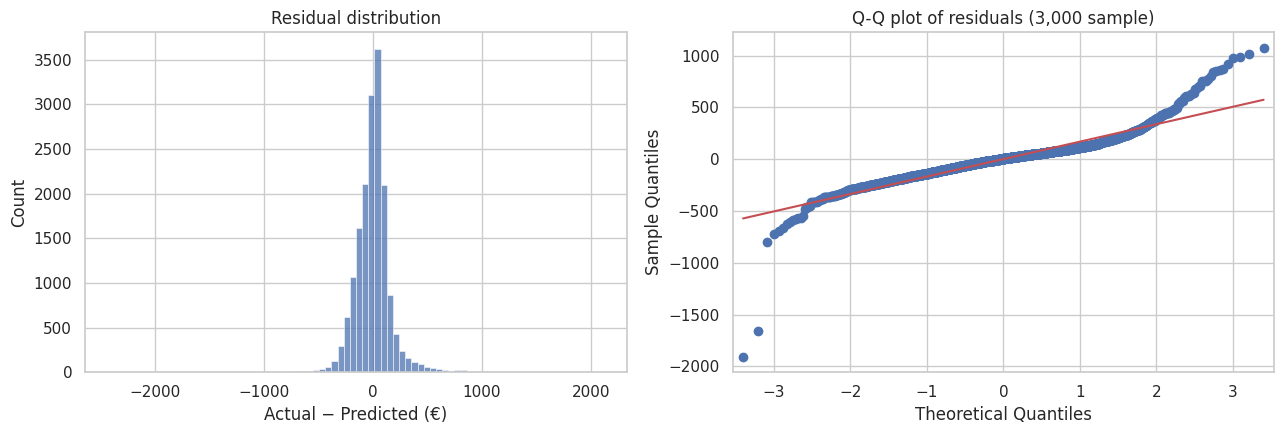

In [38]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(residuals, bins=80, ax=ax[0]); ax[0].set_title('Residual distribution'); ax[0].set_xlabel('Actual − Predicted (€)')
sm.qqplot(residuals.sample(3000, random_state=1), line='s', ax=ax[1]); ax[1].set_title('Q-Q plot of residuals (3,000 sample)')
plt.tight_layout(); plt.show()

| Assumption | Check | Result |
|---|---|---|
| **Linearity** | Actual vs predicted (Section 10) | Mostly met; predictions track actuals, weaker at high values |
| **Independence** | Random train-test split; one row per booking | Assumed. Repeat guests are rare (about 3%) |
| **Constant variance** | Residuals vs predicted (Section 10) | **Violated**: errors fan out for long, high-value stays |
| **Normal residuals** | Histogram and Q-Q plot | Approximately normal in the centre, heavy tails |
| **No perfect multicollinearity** | Weekend and week nights used, not `total_nights` (their sum); `drop_first=True` | Met. `market_segment` and `distribution_channel` overlap, which is why the channel dummies are not significant |

Coefficient estimates remain useful, but p-values for the largest bookings should be read with caution. This is common and acceptable for a business-explanation model.

## 10.3 Time-Based Validation
A random split mixes 2017 bookings into training. A stricter test trains on **2015–2016 arrivals** and predicts **2017**, which simulates using the model on future bookings.

In [39]:
past, future = model_df['arrival_date_year'] <= 2016, model_df['arrival_date_year'] == 2017
X_int = add_interactions(X)
rows = []
for name, XX in [('Model 2', X), ('Official model (with interactions)', X_int)]:
    m = LinearRegression().fit(XX[past], y[past]); p = m.predict(XX[future])
    rows.append({'Model': name, 'Test R² (2017)': r2_score(y[future], p), 'MAE (€)': mean_absolute_error(y[future], p),
                 'Actual mean (€)': y[future].mean(), 'Predicted mean (€)': p.mean()})
time_val = pd.DataFrame(rows).round(2)
print(f'Train: {past.sum():,} bookings (2015–2016) | Test: {future.sum():,} bookings (2017)')
time_val

Train: 54,127 bookings (2015–2016) | Test: 31,125 bookings (2017)


,Model,Test R² (2017),MAE (€),Actual mean (€),Predicted mean (€)
0,Model 2,0.74,120.91,454.44,436.00
1,Official model (with interactions),0.82,101.28,454.44,456.47


### Finding
On future (2017) bookings, Model 2 explains about **74%** of the variation and the official model (with interactions) about **82%**. Because `arrival_date_year` is a feature, the models learn the upward price trend (about **+€51 per booking per year**). The official model's average 2017 prediction (≈ €457) is within **€2** of the actual average (≈ €454).

### Business Meaning
The model generalizes to a future period and tracks price inflation. The year effect is a straight-line trend, though, so the model should still be **retrained regularly** (for example, quarterly) to stay accurate if price growth speeds up or slows down.

## 10.4 Improved Model: Interaction Terms
The base model assumes a summer month adds the same € at both hotels, and that a premium room adds a fixed amount regardless of stay length. **Interaction terms** relax both assumptions and keep the model a Linear Regression:
- `Resort × month`: seasonality differs by hotel.
- `nights × room type`: the room premium accrues per night.

Interaction model 5-fold CV R²: 0.840 (± 0.008)


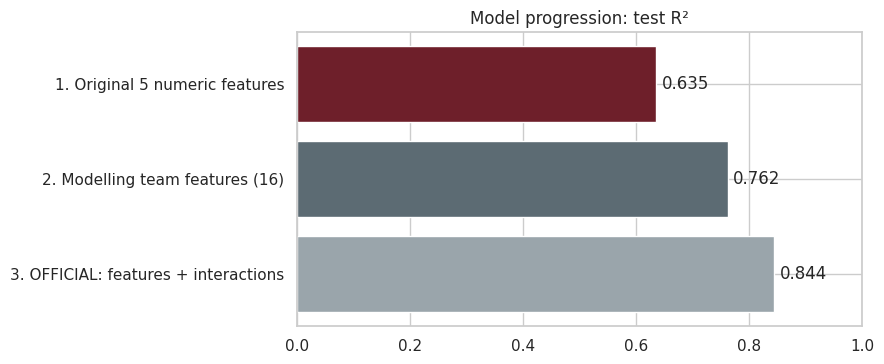

,Model,Features,Test R²,MAE (€),RMSE (€),Negative preds
0,1. Original 5 numeric features,5,0.635,137.208,220.309,3
1,2. Modelling team features (16),45,0.762,115.131,177.890,855
2,3. OFFICIAL: features + interactions,64,0.844,90.818,144.273,864


In [40]:
X_int_train, X_int_test = X_int.loc[X_train.index], X_int.loc[X_test.index]
model_int = LinearRegression().fit(X_int_train, y_train)
y_pred_int = model_int.predict(X_int_test)
progression = pd.DataFrame({
    'Model': ['1. Original 5 numeric features', '2. Modelling team features (16)', '3. OFFICIAL: features + interactions'],
    'Features': [X5.shape[1], X.shape[1], X_int.shape[1]],
    'Test R²': [r2_score(y5_te, p5), r2, r2_score(y_test, y_pred_int)],
    'MAE (€)': [mean_absolute_error(y5_te, p5), mae, mean_absolute_error(y_test, y_pred_int)],
    'RMSE (€)': [np.sqrt(mean_squared_error(y5_te, p5)), rmse, np.sqrt(mean_squared_error(y_test, y_pred_int))],
    'Negative preds': [(p5 < 0).sum(), (y_pred < 0).sum(), (y_pred_int < 0).sum()]}).round(3)
cv_int = cross_val_score(LinearRegression(), X_int_train, y_train, cv=5, scoring='r2')
print(f'Interaction model 5-fold CV R²: {cv_int.mean():.3f} (± {cv_int.std():.3f})')
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(progression['Model'][::-1], progression['Test R²'][::-1], color=['#9AA5AB', '#5C6B73', '#6E1F2A'])
for i, v in enumerate(progression['Test R²'][::-1]): ax.text(v + 0.01, i, f'{v:.3f}', va='center')
ax.set_xlim(0, 1); ax.set_title('Model progression: test R²'); plt.tight_layout(); plt.show()
progression

### Finding
Adding 19 interaction terms lifts test R² from **≈ 0.76 to ≈ 0.84** and cuts the average error from **≈ €115 to ≈ €91**, which is **64% below the baseline**. Cross-validation (R² 0.840 ± 0.008) and the 2017 holdout (R² 0.82) confirm the gain is stable. The model is still a Linear Regression, so it stays within the brief. Negative predictions remain (about 5%), so outputs should be floored at €0 in use.

### Official model
**Model 3, the modelling team's 16 features plus interaction terms, is the official model** (test R² 0.844, MAE €90.82, RMSE €144.27).
- **Model 2** (the same features, no interactions) is used to **explain** drivers (Section 11), because each coefficient has a simple meaning.
- **Model 3** is used to **predict** (Section 13) and is the headline result in the report and presentation.

*A log-transformed target was also tested and rejected: back-transforming the predictions produced extreme errors on a few bookings.*

# 11. Interpretation of Coefficients
*Interpretation & coefficients: Chimdiadi Divine Ogbobe, Aanu Adesemoye.* Based on Model 2 (main effects), whose coefficients are directly interpretable.

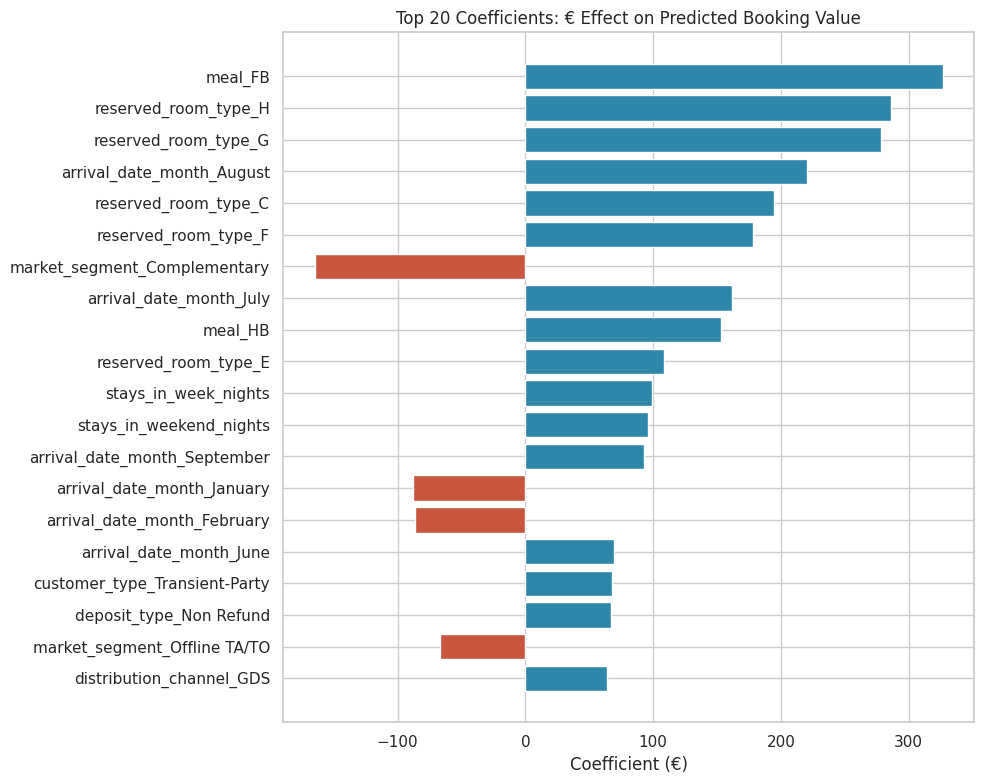

Numeric feature coefficients:
lead_time                    -0.34
arrival_date_year            51.20
stays_in_weekend_nights      95.79
stays_in_week_nights         98.80
adults                       37.37
children                     41.97
booking_changes               2.51
total_of_special_requests     6.11
dtype: float64


In [41]:
coefficients = pd.Series(model.coef_, index=X.columns)
top = coefficients.reindex(coefficients.abs().sort_values(ascending=False).index).head(20)
plt.figure(figsize=(10, 8))
plt.barh(top.index[::-1], top.values[::-1], color=['#2E86AB' if v > 0 else '#C8553D' for v in top.values[::-1]])
plt.title('Top 20 Coefficients: € Effect on Predicted Booking Value'); plt.xlabel('Coefficient (€)')
plt.tight_layout(); plt.show()
print('Numeric feature coefficients:'); print(coefficients[numeric_features].round(2))

**How to read the coefficients:** numeric coefficients are the € change per one-unit increase, for example one extra night. Category coefficients are the € difference versus the reference category: April, room A, BB meal, City Hotel, Aviation segment, Corporate channel, No Deposit and Contract customer.

| Driver | Effect | Interpretation |
|---|---|---|
| Week night / weekend night | **≈ +€99 / +€96 per night** | Each extra night adds about €97 of booking value, holding everything else constant |
| Meal FB / HB | ≈ +€327 / +€153 vs BB | Meal packages are included in ADR and add substantial value |
| Room H / G / C / F | ≈ +€178 to +€286 vs room A | Premium rooms carry much higher value |
| August / July | ≈ +€221 / +€162 vs April | Peak-season premium |
| January / February | ≈ −€87 vs April | Low-season discount |
| `arrival_date_year` | ≈ +€51 per year | Prices rise year on year |
| Complementary segment | ≈ −€165 | Free or discounted stays |
| Online TA / Direct segment | ≈ +€41 each | Same value per booking; they differ in cancellation risk |
| Resort Hotel | ≈ −€62 vs City | Once stay length is held constant, the Resort's rates are lower. Its higher value per booking comes from longer stays |
| Lead time, booking changes, special requests | ≈ €0–6 | Little effect on value. Lead time matters for cancellation, not value |
| Deposit Non Refund | ≈ +€67 | Read with caution: Non Refund bookings show a ~95% cancellation anomaly in this dataset |

These effects match what the EDA showed, which confirms the model learned real business patterns.

# 12. Business Impact Sizing
Rough € estimates for two recommendations. The data covers **26 months** (Jul-2015 to Aug-2017), so annual figures = period figures × 12 / 26. **These are illustrative scenarios, not forecasts.**

In [42]:
months_covered = df.groupby(['arrival_date_year', 'arrival_date_month'], observed=True).ngroups
annual = 12 / months_covered

ota = df[df['market_segment'] == 'Online TA']
ota_rate = ota['is_canceled'].mean()
ota_cancelled_value = ota.loc[ota['is_canceled'] == 1, 'revenue'].sum()

stays = non_cancelled
n_room_a = (stays['reserved_room_type'] == 'A').sum()
uplift_a_to_d = stays.loc[stays['reserved_room_type'] == 'D', 'revenue'].mean() - stays.loc[stays['reserved_room_type'] == 'A', 'revenue'].mean()

rows = []
for pp in [2, 5, 10]:
    v = ota_cancelled_value * (pp / 100) / ota_rate
    rows.append({'Lever': 'Reduce Online TA cancellation rate', 'Scenario': f'−{pp} pp ({ota_rate:.1%} → {ota_rate - pp/100:.1%})',
                 'Period value (€)': v, 'Per year (€)': v * annual})
for share in [0.02, 0.05, 0.10]:
    v = n_room_a * share * uplift_a_to_d
    rows.append({'Lever': 'Upsell room A → D', 'Scenario': f'{share:.0%} of room-A stays',
                 'Period value (€)': v, 'Per year (€)': v * annual})
impact = pd.DataFrame(rows)
print(f'Months covered: {months_covered} | Online TA cancelled value: €{ota_cancelled_value:,.0f} | A→D uplift per stay: €{uplift_a_to_d:,.0f}')
impact.style.format({'Period value (€)': '€{:,.0f}', 'Per year (€)': '€{:,.0f}'})

Months covered: 26 | Online TA cancelled value: €9,252,085 | A→D uplift per stay: €180


,Lever,Scenario,Period value (€),Per year (€)
0,Reduce Online TA cancellation rate,−2 pp (35.5% → 33.5%),"€520,571","€240,263"
1,Reduce Online TA cancellation rate,−5 pp (35.5% → 30.5%),"€1,301,427","€600,659"
2,Reduce Online TA cancellation rate,−10 pp (35.5% → 25.5%),"€2,602,854","€1,201,317"
3,Upsell room A → D,2% of room-A stays,"€146,600","€67,662"
4,Upsell room A → D,5% of room-A stays,"€366,500","€169,154"
5,Upsell room A → D,10% of room-A stays,"€733,000","€338,308"


### How to read this
- **Cancellation lever:** retained value scales with the cancellation rate. Each percentage point of Online TA cancellations removed is worth about **€0.12M per year**, so a 5-point cut is worth about **€0.6M per year**.
- **Upsell lever:** a 5% A → D upgrade rate is worth about **€0.17M per year**. This is an **upper bound**, because D bookings also tend to be longer stays, so part of the gap is not caused by the room itself.
- **Caveats:** booking value before commissions, costs and any discount needed to drive the behaviour change.

# 13. Interactive Booking Value Estimator
Uses the **official model** (Model 3, with interactions). The two fixed scenarios below always print; the interactive sliders appear when the notebook runs in Jupyter with `ipywidgets` installed.

In [43]:
def estimate(hotel='City Hotel', month='January', room='A', weekend_nights=1, week_nights=3, adults=2, children=0,
             segment='Online TA', channel='TA/TO', meal='BB', customer='Transient', deposit='No Deposit',
             lead_time=60, year=2017, booking_changes=0, special_requests=1):
    row = pd.DataFrame([{'lead_time': lead_time, 'arrival_date_year': year, 'stays_in_weekend_nights': weekend_nights,
                         'stays_in_week_nights': week_nights, 'adults': adults, 'children': children,
                         'booking_changes': booking_changes, 'total_of_special_requests': special_requests,
                         'hotel': hotel, 'arrival_date_month': month, 'meal': meal, 'market_segment': segment,
                         'distribution_channel': channel, 'reserved_room_type': room, 'deposit_type': deposit,
                         'customer_type': customer}])
    x = pd.get_dummies(row, columns=categorical_features, dtype=int).reindex(columns=X.columns, fill_value=0)
    x = add_interactions(x).reindex(columns=X_int.columns, fill_value=0)
    return max(model_int.predict(x)[0], 0)

low  = estimate(hotel='City Hotel',   month='January', room='A')
high = estimate(hotel='Resort Hotel', month='August',  room='G')
print('4 nights (1 weekend + 3 week), 2 adults, Online TA, 2017:')
print(f'  City Hotel,   January, room A → €{low:,.0f}')
print(f'  Resort Hotel, August,  room G → €{high:,.0f}   ({high / low:.1f}× the value)')

4 nights (1 weekend + 3 week), 2 adults, Online TA, 2017:
  City Hotel,   January, room A → €370
  Resort Hotel, August,  room G → €1,028   (2.8× the value)


In [44]:
try:
    import ipywidgets as w
    def show(hotel, month, room, nights, adults, segment):
        wk = min(2, nights // 3)   # simple split of the stay into weekend and week nights
        print(f'Predicted booking value: €{estimate(hotel=hotel, month=month, room=room, weekend_nights=wk, week_nights=nights - wk, adults=adults, segment=segment):,.0f}')
    w.interact(show, hotel=['City Hotel', 'Resort Hotel'], month=MONTHS, room=list('ABCDEFGH'),
               nights=w.IntSlider(value=4, min=1, max=14), adults=w.IntSlider(value=2, min=1, max=4),
               segment=['Online TA', 'Direct', 'Offline TA/TO', 'Corporate', 'Groups'])
except ImportError:
    print('Install ipywidgets (pip install ipywidgets) to enable the interactive estimator.')

interactive(children=(Dropdown(description='hotel', options=('City Hotel', 'Resort Hotel'), value='City Hotel'…

# 14. Integrated Findings

| # | Finding | Evidence (EDA / SQL / Model) |
|---|---|---|
| 1 | Cancellations are the largest revenue leak | 27.8% of bookings; €11.43M of €34.31M (33.3%) booking value cancelled |
| 2 | Online TA is the least reliable channel | 35.5% cancel rate vs about 15% Direct / Offline; retains only 58% of booked value |
| 3 | Length of stay is the strongest revenue driver | Correlation 0.75; ≈ +€96–99 per extra night in the model |
| 4 | Premium rooms and meal plans raise value | Rooms C/G/H ≈ €640–730 per stay vs €294 for room A; FB ≈ +€327 |
| 5 | Strong seasonality | ADR €72 (Jan) → €152 (Aug); May/Apr/Jun busiest per year; Nov–Jan weakest |
| 6 | Lead time predicts cancellation, not value | Value correlation 0.29; cancel rate 8% → ~42% as lead time grows |
| 7 | Revenue is predictable | Official model R² 0.844, MAE €91 (64% below baseline); 2017 holdout R² 0.82 |
| 8 | Prices rise year on year | ≈ +€51 per booking per year; with the year feature, the 2017 average prediction is within €2 |
| 9 | Channels differ in reliability, not value | Online TA and Direct carry the same value (≈ +€41 each) but cancel at 35.5% vs 14.8% |

# 15. Recommendations

| Recommendation | Reason | Illustrative value |
|---|---|---|
| Deposits or partial prepayment for long-lead and peak-season Online TA bookings | Highest cancellation exposure | ≈ €0.6M / year per 5 pp cut |
| Grow direct bookings (best-rate guarantee, member pricing) | Similar value to OTA, much lower cancellation, no commission | Lower risk and commission |
| Peak-season pricing and minimum-stay rules (July–August) | Highest ADR and demand | Higher revenue per available room |
| Raise spring prices and upsell in April–June | Highest volume per year at mid-level rates | Capture under-priced demand |
| Multi-night winter packages (Nov–Jan) | Low demand; stay length drives value | ≈ +€96–99 per extra night |
| Room and meal-plan upgrades at booking and pre-arrival | Premium rooms and FB/HB add €150–320 per stay | ≤ €0.17M / year at 5% A → D |
| Track retained revenue by channel; retrain the model quarterly | Booked value overstates Online TA; price trends can change | Better decisions, accurate forecasts |

# 16. Ethics, Privacy & Responsible Use
- **Personal data:** the dataset holds no names, but **country + arrival date + party size** can re-identify guests. Under **GDPR** (EU hotels), aggregate data before sharing it in dashboards and limit guest-level access to people who need it.
- **Fair use of predictions:** the model should support pricing, not personalize prices by nationality. `country` was deliberately left out of the model.
- **Human in the loop:** predictions can be negative, and price trends can change (Section 10.3). Revenue managers should review model outputs before acting on them.

# 17. Conclusion
UrbanNest's hotels are busy, but about a third of booked value never turns into revenue. The analysis points to three levers: **protect** revenue from cancellations (especially Online TA and long-lead bookings), **time** pricing around strong seasonal demand, and **grow** the value of each booking through longer stays and premium rooms.

The official Linear Regression model (the modelling team's 16 features plus interaction terms) explains about **84%** of the variation in booking value, with an average error of **€91**. It holds up on future data (2017 R² 0.82) and tracks the year-on-year price trend, but it should be retrained regularly. It is a strong **decision-support tool**, not yet a standalone pricing engine.

**Next steps:**
1. Build a cancellation-prediction model (logistic regression), so expected revenue = P(stay) × predicted value.
2. Add commission, cost and competitor-rate data to move from revenue toward profitability analysis.
3. Retrain quarterly and monitor prediction error over time.

# Appendix A: Data Dictionary (columns used)

| Column | Type | Unit / values | Description |
|---|---|---|---|
| `hotel` | Category | City Hotel, Resort Hotel | Property |
| `is_canceled` | Binary | 0 / 1 | 1 = booking was cancelled |
| `lead_time` | Integer | Days | Days between booking and arrival |
| `arrival_date_year` / `_month` | Integer / category | 2015–2017 / January–December | Arrival date |
| `stays_in_weekend_nights` / `stays_in_week_nights` | Integer | Nights | Nights booked |
| `total_nights` | Integer | Nights | Weekend + week nights (engineered) |
| `adults`, `children`, `babies` | Integer | People | Party size |
| `meal` | Category | BB, HB, FB, SC | Meal plan (bed and breakfast, half board, full board, self-catering) |
| `market_segment` | Category | Online TA, Direct, … | How the booking was sold |
| `distribution_channel` | Category | TA/TO, Direct, Corporate, GDS | Channel the booking came through |
| `deposit_type` | Category | No Deposit, Non Refund, Refundable | Deposit terms |
| `booking_changes` | Integer | Count | Changes made to the booking before arrival |
| `total_of_special_requests` | Integer | Count | Special requests made by the guest |
| `reserved_room_type` | Category | A–H, L (anonymized) | Room type booked |
| `customer_type` | Category | Transient, Contract, Group, Transient-Party | Booking type |
| `adr` | Float | € per night | Average daily rate |
| `revenue` | Float | € | `adr × total_nights` = booking value (engineered target) |

# Appendix B: Brief Compliance Checklist

| Brief requirement | Where it is covered |
|---|---|
| Explain the business problem, why revenue prediction matters, and how it improves pricing, occupancy and profitability | Section 2 |
| Load and inspect the dataset in Python | Section 4 |
| Clean the data (missing values, duplicates) | Section 5 |
| Extensive EDA with plain-language explanations | Section 6 (10 analyses, each with Finding and Business Meaning) |
| SQL: room types, months/seasons, customer segments | Section 7 and `group3_hotel_analysis.sql` |
| Separate X and y; train_test_split; explain why | Section 8 |
| Linear Regression with scikit-learn; predictions; explain what the model does | Section 9 (Model 2) and Section 10.4 (official Model 3) |
| Evaluate; explain the score; good or poor; what affects it | Sections 10–10.4 |
| Interpret results in simple language | Sections 11–15 and 17 |

In [45]:
conn.close()